### Individual inversions of apparent resistivities and travel times (ERT and RST) 

All rights reserved. Material from GEOFCAN 2025 Workshop led by Coline Mollaret

In [1]:
import time 
t = time.time() # get current time to check the time to run the script

In [2]:
#############################################
import sys, os
from pathlib import Path
# try and except functions to change the directory only once to stay in the right folder even the script/cell is run again
try:  
    findpaths
except NameError:  
    os.chdir(os.path.abspath("..")) #to find the folder where the data are stored
    findpaths=True
print(os.getcwd()) #print the current working directory
#############################################

/home/jovyan/work/4pm-pji


In [3]:
# import python packages
import numpy as np
import pygimli as pg
from pygimli.physics import Refraction, ERTManager
from pygimli.physics.traveltime import createGradientModel2D
import pygimli.physics.traveltime as tt
from pygimli.physics import ert
import pandas as pd
from datetime import datetime
from fpinv import FourPhaseModel, FourPhaseModelSomerton # load petrophysical equations
from fpinv import add_inner_title, set_style, minmax # load functions

import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR) # to get rid of "matplotlib.font_manager - WARNING - findfont: Font family 'Roboto' not found."

save_stats = 1
fs=12
set_style(fs, style="default")

### PROFILE ###################################################################
#profile='CH_COR_V01_2007-07-13_01' # change name of your profile 
#profile='CH_DOL_V01_2016-08-11_01'
#profile = 'KG_ABR_P03_2021-08-22_01'
profile='CH_LAP_MH1_2010-08-24_01'
#profile='3L'

print("profile: " + profile)

profile: CH_LAP_MH1_2010-08-24_01


In [4]:
###############################################################################
# Import profile specific settings if they exist, otherwise import standard settings:
if os.path.exists(os.path.abspath('profile_settings/'+profile+'_settings.py')):
    exec(open('profile_settings/'+profile+'_settings.py', 'r').read()) # reads site specific settings
    print('profile settings exist and were loaded')
else:
    from settings import *
    print('profile settings do not exist, default was loaded')

##### Creates new directories if not existing yet
Path(os.getcwd()+'/results/inversion/').mkdir(parents=True, exist_ok=True)
Path(os.getcwd()+'/results/rst_process/').mkdir(parents=True, exist_ok=True)

###############################################################################
now = datetime.now() # datetime object containing current date and time
date_string = now.strftime("%d/%m/%Y %H:%M:%S") # dd/mm/YY H:M:S    

### MESH ######################################################################
#Load meshes
mesh = pg.load('results/mesh/' + profile + '_mesh.bms')
paraDomain = pg.load('results/mesh/' + profile +"_paraDomain.bms")
#depth = mesh.ymax() - mesh.ymin()

profile settings exist and were loaded


In [5]:
### ERT #######################################################################
# Load ERT data and compute the geometric factor k
ertData = pg.DataContainerERT('results/filtered_data/' + profile +"_ert_filtered.data")
ertData['k'] = ert.createGeometricFactors(ertData, numerical=True)
print('\n',ertData)

13/10/25 - 10:52:10 - pyGIMLi - INFO - Cache /opt/conda/lib/python3.10/site-packages/pygimli/physics/ert/ert.py:createGeometricFactors restored (1.1s x 3): /home/jovyan/.cache/pygimli/4479681560088247646



 Data: Sensors: 43 data: 276, nonzero entries: ['a', 'b', 'err', 'i', 'k', 'm', 'n', 'r', 'rhoa', 'u', 'valid']


In [6]:
### ERT inversion ########
###########################
ert = ERTManager()
resinv = ert.invert(ertData, mesh=mesh, lam=lame, zWeight=zWeighte, maxIter=maxItere, verbose=True)
rmschi1=f'RMS: {ert.inv.relrms():.2f} %  |  $\chi^{2}$: {ert.inv.chi2():.2f}'
print("ERT ",rmschi1)

13/10/25 - 10:52:10 - pyGIMLi - INFO - Found 2 regions.
13/10/25 - 10:52:10 - pyGIMLi - INFO - (ERTModelling) Region with smallest marker (1) set to background.
13/10/25 - 10:52:10 - pyGIMLi - INFO - Creating forward mesh from region infos.
13/10/25 - 10:52:10 - pyGIMLi - INFO - Creating refined mesh (H2) to solve forward task.
13/10/25 - 10:52:10 - pyGIMLi - INFO - Mesh for forward task: Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
13/10/25 - 10:52:10 - pyGIMLi - INFO - Use median(data values)=8842.038404081495


min/max(dweight) = 33.3333/33.3333


13/10/25 - 10:52:10 - pyGIMLi - INFO - Created startmodel from forward operator: 1188, min/max=8842.038404/8842.038404
13/10/25 - 10:52:10 - pyGIMLi - INFO - Starting inversion.


fop: <pygimli.physics.ert.ertModelling.ERTModelling object at 0x7f5a765cc450>
Data transformation: <pgcore._pygimli_.RTransLogLU object at 0x7f5a765cc680>
Model transformation (cumulative):
	 0 <pgcore._pygimli_.RTransLogLU object at 0x7f5a765b5a10>
min/max (data): 2939/2.1e+04
min/max (error): 3%/3%
min/max (start model): 8842/8842
--------------------------------------------------------------------------------
use model trans from RegionManager
Calculating response for model: min = 8842.04 max = 8842.04
Allocating memory for primary potential...... 0.00787405

No primary potential for secondary field calculation with topography.
Creating P2-Primmesh:		Nodes: 14463	Cells: 7092	Boundaries: 10777
ModellingBase::setMesh() copying new mesh ... Found topography for surface=0.675 : 0.625
Found datafile: 43 electrodes
Found: 43 node-electrodes
rMin = 1.99563, rMax = 333.963
NGauLeg + NGauLag for inverse Fouriertransformation: 13 + 4
Found non-Neumann domain
0.0240135 s
FOP updating mesh depe

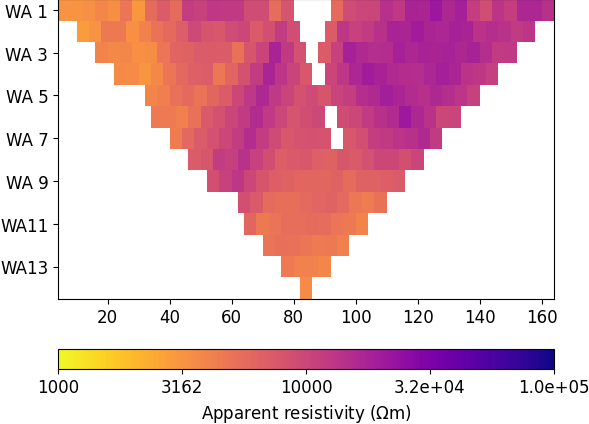

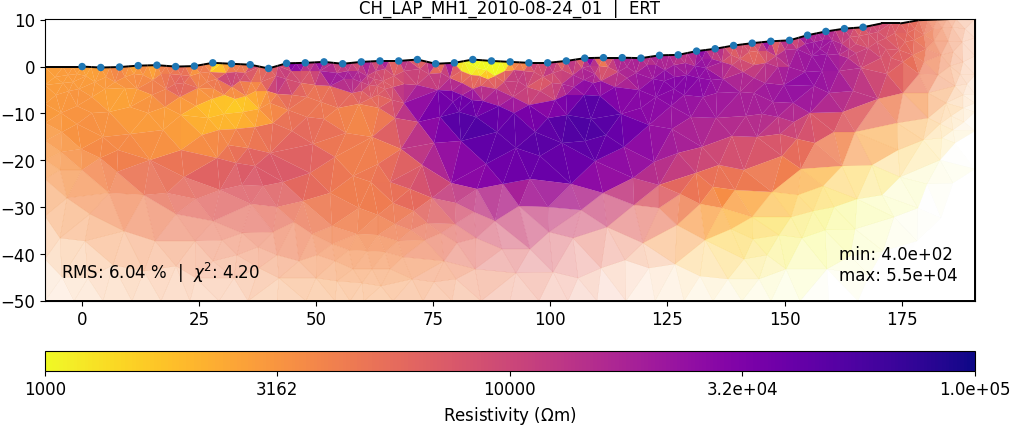

In [7]:
### ERT Plots  ###################################
##################################################

# Plot apparent resistivities
pg.show(ertData, cMap=cMape, cMin=cMine, cMax=cMaxe)

# Plot ERT individual inverion
fig, ax = pg.plt.subplots(figsize=(12,6))
ert.showResult(resinv, ax, cMin=cMine, cMax=cMaxe, logScale=True, cMap=cMape)
ax.set_title(profile+'  |  ERT',fontsize=fs)
add_inner_title(ax, rmschi1, borderpad=1, loc=3, size=fs, fw="regular", frame=True)
add_inner_title(ax, minmax(resinv), borderpad=1, loc=4, size=fs, fw="regular", frame=True)
    
np.savetxt('results/inversion/'+profile + "_res_conventional.dat", resinv)
pg.plt.savefig('results/inversion/'+profile+'_ERT_TOM.png', dpi=100)

In [8]:
### Refraction Seismic Tomography (RST) ###############################
#######################################################################
# Load RST data
ttData = pg.DataContainer('results/filtered_data/' + profile+"_rst_filtered.data", "s g")
rst = Refraction(ttData)

# if not defined in the settings file, default values are used (defined below)
try: vBottom  
except NameError: vTop, vBottom = 500, 10000 

In [9]:
##### RST inversion ###################################################
#######################################################################
rst.setMesh(mesh)
startmodel = createGradientModel2D(ttData, paraDomain, vTop, vBottom)
np.savetxt('results/rst_process/'+profile +"_rst_startmodel.dat", 1/startmodel)
vest = rst.invert(ttData, mesh=paraDomain, err=rste, zWeight=zWeights, lam=lams, startModel=startmodel, verbose=True, maxIter=maxIters) #, secNodes=secNodes
# vest = rst.inv.runChi1()
rmschi2=f'RMS: {(rst.inv.absrms())*1000:.2f} ms  |  $\chi^{2}$: {rst.inv.chi2():.1f}'
print("\nRST ",rmschi2)


13/10/25 - 10:52:50 - pyGIMLi - INFO - Found 2 regions.
13/10/25 - 10:52:50 - pyGIMLi - INFO - Region with smallest marker set to background (marker=1)
13/10/25 - 10:52:50 - pyGIMLi - INFO - Found 1 regions.
13/10/25 - 10:52:50 - pyGIMLi - INFO - Creating forward mesh from region infos.
13/10/25 - 10:52:50 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.
13/10/25 - 10:52:50 - pyGIMLi - INFO - Starting inversion.


min/max(dweight) = 1000/1000
fop: <pygimli.physics.traveltime.modelling.TravelTimeDijkstraModelling object at 0x7f5a6af17a60>
Data transformation: <pgcore._pygimli_.RTrans object at 0x7f5a6ad6d9e0>
Model transformation (cumulative):
	 0 <pgcore._pygimli_.RTransLogLU object at 0x7f5a6aee2ab0>
min/max (data): 0.0029/0.11
min/max (error): 0.94%/34.36%
min/max (start model): 1.0e-04/0.005
--------------------------------------------------------------------------------
use model trans from RegionManager
min/max(dweight) = 1000/1000
Building constraints matrix
constraint matrix of size(nBounds x nModel) 1706 x 1188
check Jacobian: wrong dimensions: (0x0) should be (548x1188)  force: 1
jacobian size invalid, forced recalc: 1
--------------------------------------------------------------------------------
inv.iter 1 ... calculating jacobian matrix (forced=1)...... 0.34196 s
min data = 0.00291 max data = 0.10666 (548)
min error = 0.00937559 max error = 0.343643 (548)
min response = 0.01415 max 

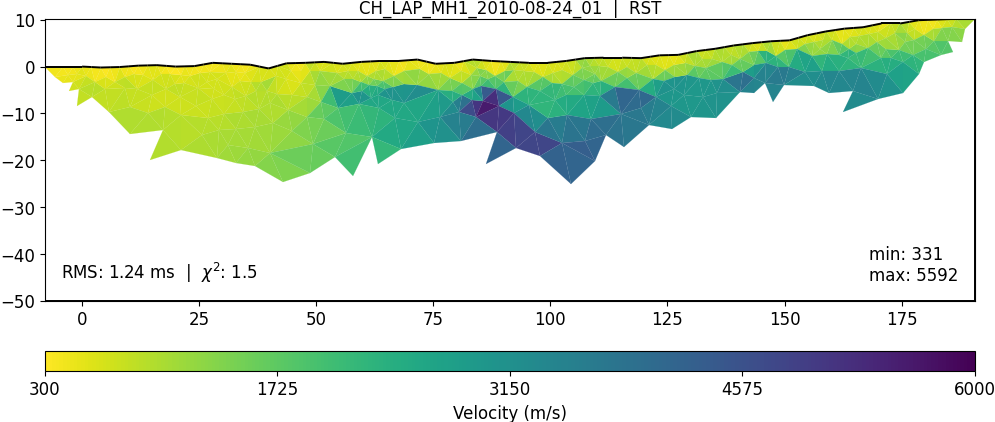

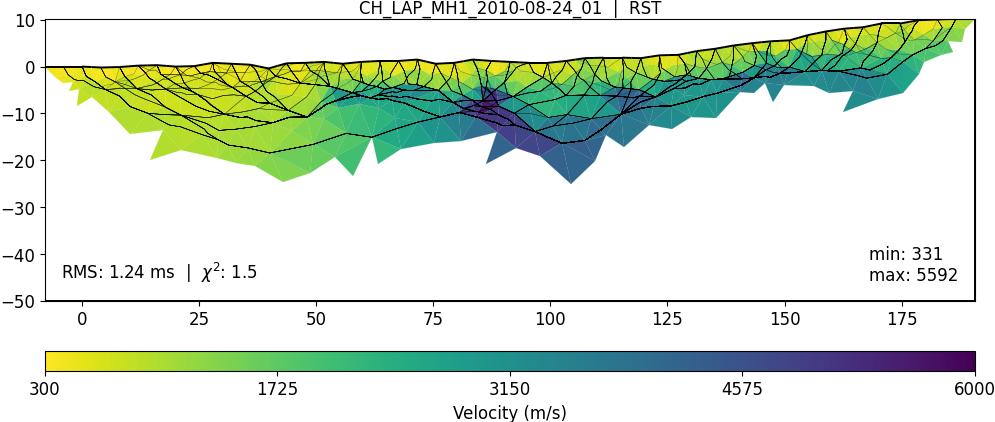

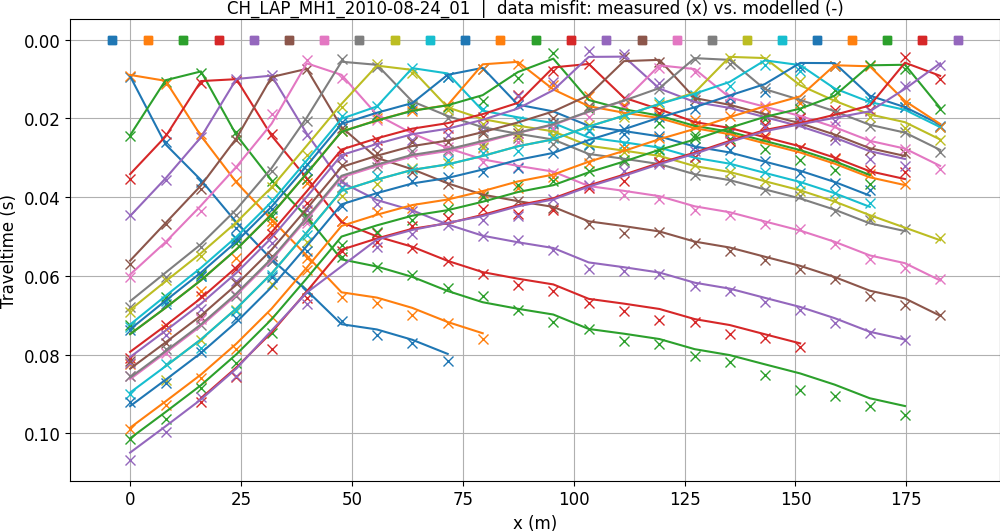

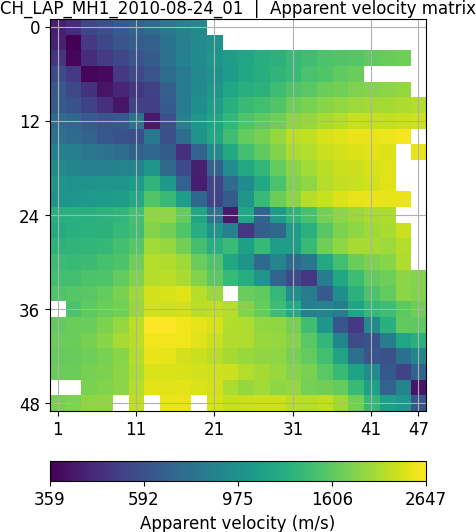

In [10]:
#########################################################
####### RST Plots   #####################################
#########################################################
# Plot seismic tomogram
fig, ax = pg.plt.subplots(figsize=(12,6))
rst.showResult(vest,ax,cMin=cMins, cMax=cMaxs, logScale=False, cMap=cMaps, coverage=rst.standardizedCoverage())
ax.set_title(profile + '  |  RST', fontsize=fs)
add_inner_title(ax, rmschi2, borderpad=1, loc=3, size=fs, fw="regular", frame=True)
add_inner_title(ax, minmax(vest), borderpad=1, loc=4, size=fs, fw="regular", frame=True)
rst.rayCoverage().save('results/rst_process/'+profile + "_rst_coverage.dat")
np.savetxt('results/inversion/'+profile + "_vel_conventional.dat", vest)
pg.plt.savefig('results/inversion/'+profile+'_RST_TOM.png', dpi=100)

# plot Seismic tomogram with computed ray paths
fig, ax = pg.plt.subplots(figsize=(12,6))
rst.showResult(vest,ax,cMin=cMins, cMax=cMaxs, logScale=False, cMap=cMaps, coverage=rst.standardizedCoverage())
rst.drawRayPaths(ax=ax, lw=0.3, alpha=0.5, color='black')
ax.set_title(profile + '  |  RST', fontsize=fs)
add_inner_title(ax, rmschi2, borderpad=1, loc=3, size=fs, fw="regular", frame=True)
add_inner_title(ax, minmax(vest), borderpad=1, loc=4, size=fs, fw="regular", frame=True)
rst.rayCoverage().save('results/rst_process/'+profile + "_rst_coverage.dat")
np.savetxt('results/inversion/'+profile + "_vel_conventional.dat", vest)
pg.plt.savefig('results/inversion/'+profile+'_RST_rays.png', dpi=100)
    

# Plot travel time (gradient) start model 
#pg.show(paraDomain, 1/startmodel, cMap="viridis_r")
    
# Plot Picks
#fig, ax = pg.plt.subplots(figsize=(12,6))
#rst.showData(ax=ax,firstPicks=True, linewidth=0.4, markersize=3)
#tt.drawFirstPicks(ax, ttData, marker=None, lw=0.75)
#ax.set_title(profile+'  |  Picks', fontsize=fs)
#pg.plt.gca().invert_yaxis()
#pg.plt.savefig('results/inversion/'+profile+'_RST_Picks.png')
    
# Plot Data misfit (measured (crosses) and modelled (lines) traveltimes)
fig, ax = pg.plt.subplots(figsize=(12,6))
rst.showData(ax=ax,firstPicks=True, linewidth=0, markersize=7)
tt.drawFirstPicks(ax, ttData, rst.inv.response, marker=None, lw=1.5)
ax.set_title(profile+'  |  data misfit: measured (x) vs. modelled (-)', fontsize=fs)
pg.plt.gca().invert_yaxis()
pg.plt.savefig('results/inversion/'+profile+'_RST_DataMisfit.png', dpi=100)

# Plot Apparent velocity matrix
fig, ax = pg.plt.subplots(figsize=(12,6))
rst.showData(ax=ax)
ax.set_title(profile+'  |  Apparent velocity matrix', fontsize=fs)
pg.plt.savefig('results/inversion/'+profile+'_RST_AppVelocity.png', dpi=100)

In [11]:
print(os.getcwd()) #print the current working directory


/home/jovyan/work/4pm-pji


In [12]:

###############################################################################
### Save inversion parameters and error stats to csv file in results
save_stats=1
if save_stats ==1:
    if os.path.exists(os.path.abspath("results/ert_rst_stats.csv")) == True:
        ert_rst_stats = pd.read_csv('results/ert_rst_stats.csv', index_col = False) 
        print("existed file read")
    else:
        ert_rst_stats = pd.DataFrame(index=(range(0,1)), columns = ['profile', 'startmodel min', 'startmodel max', 'lams', 'lame', 'zWeights', 'zWeighte',
                                                                    'RST RMS (ms)', 'RST RMS (%)','RST Chi2', 'ERT RMS', 'ERT Chi2']) # empty df to fill values


    ert_rst_stats_new = pd.DataFrame(index=(range(0,1)), columns = ['profile', 'startmodel min', 'startmodel max', 'lams', 'lame', 'zWeights', 'zWeighte',
                                                                    'RST RMS (ms)', 'RST RMS (%)', 'RST Chi2', 'ERT RMS', 'ERT Chi2'])

    
    rms = rst.inv.inv.relrms()       # rel RST rms error (%)
    rms_ms = (rst.inv.absrms())*1000 # abs RST rms error in ms(!)
    chi2 = rst.inv.inv.chi2()        # RST chi2
        
    
    
    ert_rms = ert.inv.inv.relrms()  # rel ERT rms error
    ert_chi2 = ert.inv.inv.chi2()   # ERT chi2

    #show RST rms both in % and in ms
    ert_rst_stats_new = {'profile':profile,'startmodel min': vTop,'startmodel max': vBottom,
                         'lams':lams,'lame':lame,'zWeights':zWeights,'zWeighte':zWeighte,
                         'RST RMS (ms)':np.round(rms_ms,1),'RST RMS (%)':np.round(rms,1), 'RST Chi2':np.round(chi2,1), 
                         'ERT RMS':np.round(ert_rms,1),'ERT Chi2':np.round(ert_chi2,1)} # empty dataframe to store inversion parameters

    df2 = pd.DataFrame([ert_rst_stats_new]) # makes dataframe out of structure above
    df2.reset_index(drop = True, inplace = True)
    ert_rst_stats.reset_index(drop = True, inplace = True)

    # Add new row to metadata file
    ert_rst_stats = pd.concat([ert_rst_stats, df2],ignore_index = True) 
    print( ert_rst_stats)
    # remove empty rows
    ert_rst_stats.dropna(how='all',inplace = True)
    # remove duplicates
    #ert_rst_stats.drop_duplicates(['startmodel min','startmodel max','lams','lame','zWeights','zWeighte'], inplace=True, keep='last')

    print('\n\nINV STATS:')
    print("-" * 50)
    print(ert_rst_stats[['profile', 'RST RMS (ms)', 'RST RMS (%)', 'RST Chi2','ERT RMS', 'ERT Chi2', 'lams', 'lame', 'zWeights', 'zWeighte']])

    # Save metadata to csv file
    ert_rst_stats.to_csv(os.path.abspath('results/ert_rst_stats.csv'), index=False)  
else:
    print('\n\nIndividual INV ERRORS:')
    print("-" * 30)
    print("ERT ",rmschi1)
    print("RST ",rmschi2)
    

### Write individual rms errors in profile settings.py
now = datetime.now() # datetime object containing current date and time
date_string = now.strftime("%d/%m/%Y %H:%M:%S") # dd/mm/YY H:M:S

path=os.getcwd()
fileW = path+'/profile_settings/'+profile+"_settings.py"
f = open(fileW, 'a')

# f.write("\nindiv_rst_rms = %.2f" %( rst.inv.relrms()))
f.write("\nindiv_rst_rms_ms   = %.2f" %( rst.inv.absrms()*1000))
f.write("\nindiv_rst_chi2   = %.2f" %(rst.inv.chi2()))
# f.write(f'RMS: {(rst.inv.absrms())*1000:.1f} ms')
    
f.write("\nindiv_ert_rms_perc = %.2f" %( ert.inv.relrms()))
f.write("\nindiv_ert_chi2 = %.2f" %( ert.inv.chi2()))

f.write("  # %s\n" %(date_string))
f.close()

existed file read
                    profile  startmodel min  startmodel max  lams  lame  \
0  CH_LAP_MH1_2010-08-24_01             200           10000    30    10   
1  CH_LAP_MH1_2010-08-24_01             200           10000    30    10   

   zWeights  zWeighte  RST RMS (ms)  RST RMS (%)  RST Chi2  ERT RMS  ERT Chi2  
0       0.2      0.25           1.2          5.7       1.5      6.0       4.2  
1       0.2      0.25           1.2          5.7       1.5      6.0       4.2  


INV STATS:
--------------------------------------------------
                    profile  RST RMS (ms)  RST RMS (%)  RST Chi2  ERT RMS  \
0  CH_LAP_MH1_2010-08-24_01           1.2          5.7       1.5      6.0   
1  CH_LAP_MH1_2010-08-24_01           1.2          5.7       1.5      6.0   

   ERT Chi2  lams  lame  zWeights  zWeighte  
0       4.2    30    10       0.2      0.25  
1       4.2    30    10       0.2      0.25  


In [13]:
#############################################
# Compute directly the 4 phases content through the 4PM equations (i.e. without joint inversion!)

# Archie's law by default (if not given)
try: equa
except NameError:  equa='A'

# Resistivity Geometric Mean Model
if equa == 'G':
    fpm = FourPhaseModelSomerton(phi=poro, rhow=rhow, rhoi=rhoi, rhoa=rhoa, rhor=rhor, vr=vr)  
    print('Petropyhsical model chosen: Geometric mean model \n')
    fae, fie, fwe, maske = fpm.all(resinv, vest)
    fre = 1 - fae - fie - fwe
    print("4PM results using the geometric mean model: ")
    print("water content min and max: ", np.round(np.min(fwe), 2), np.round(np.max(fwe), 2))
    print("ice content min and max: ", np.round(np.min(fie), 2), np.round(np.max(fie), 2))
    print("air content min and max: ", np.round(np.min(fae), 2), np.round(np.max(fae), 2))
    np.savez('results/inversion/'+ profile + "_conventional_"+equa+".npz", vel=np.array(vest), rho=np.array(resinv), fa=fae,
         fi=fie, fw=fwe, mask=maske)
    
 # Archie's law
elif equa== 'A':
    fpm = FourPhaseModel(vw=vw, vi=vi, va=va, vr=vr, phi=poro, n=n, m=m, a=a, rhow=rhow)
    print("Petropyhsical model chosen: Archie's law \n")
    fae, fie, fwe, maske = fpm.all(resinv, vest)
    fre = 1 - fae - fie - fwe
    print("4PM results using Archie's law: ")
    print("water content min and max: ", np.round(np.min(fwe), 2), np.round(np.max(fwe), 2))
    print("ice content min and max: ", np.round(np.min(fie), 2), np.round(np.max(fie), 2))
    print("air content min and max: ", np.round(np.min(fae), 2), np.round(np.max(fae), 2))
    print("\n")
    np.savez('results/inversion/'+ profile + "_conventional.npz", vel=np.array(vest), rho=np.array(resinv), fa=fae,
         fi=fie, fw=fwe, mask=maske)



Petropyhsical model chosen: Archie's law 

4PM results using Archie's law: 
water content min and max:  0.06 0.4
ice content min and max:  -0.65 0.35
air content min and max:  -0.02 0.9




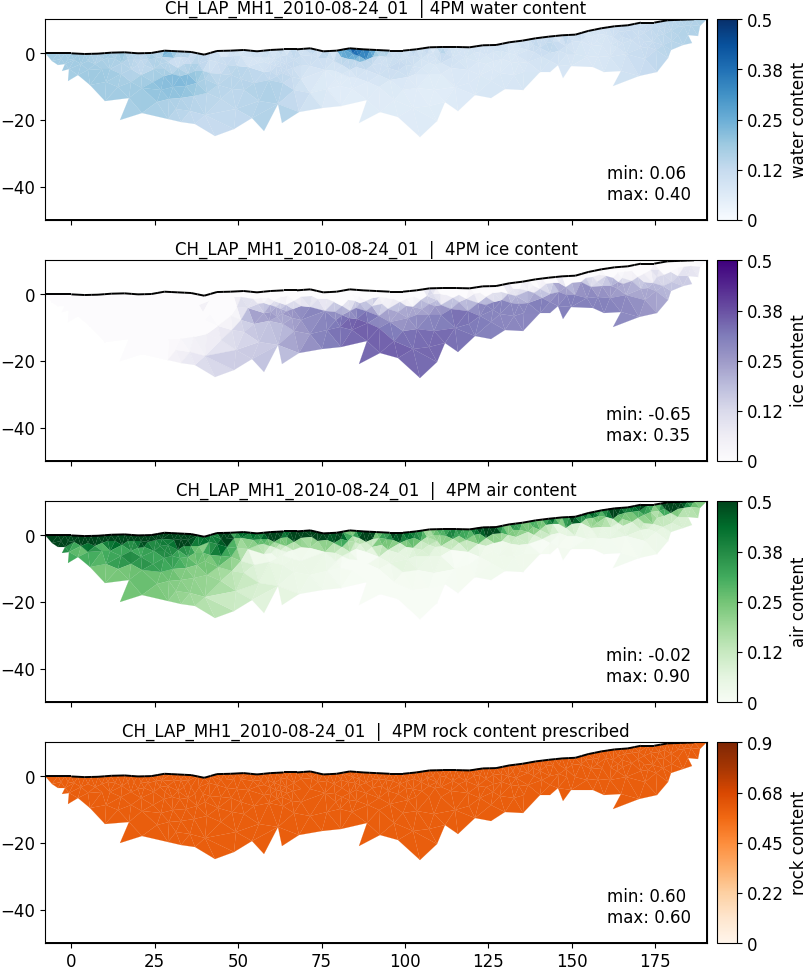

In [14]:
# Plot 4PM analytical solution (i.e. without PJI)
# The 4PM (Hauck et al. 2011) applies petrophysical equation analytically to estimate the 3 pore phase contents.
# The porosity needs to be assumed and prescribed!

fig, ax = pg.plt.subplots(4,sharex=True,figsize=(12,12))

rst.showResult(fwe,ax[0],cMin=cMinw, cMax=cMaxw, logScale=False, cMap=cMapw, label="water content", orientation="vertical", coverage=rst.standardizedCoverage())
ax[0].set_title(profile + '  | 4PM water content', fontsize=fs)
add_inner_title(ax[0], minmax(fwe), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

rst.showResult(fie,ax[1],cMin=cMini, cMax=cMaxi, logScale=False, cMap=cMapi, label="ice content", orientation="vertical", coverage=rst.standardizedCoverage())
ax[1].set_title(profile + '  |  4PM ice content', fontsize=fs)
add_inner_title(ax[1], minmax(fie), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

rst.showResult(fae,ax[2],cMin=cMina, cMax=cMaxa, logScale=False, cMap=cMapa, label="air content", orientation="vertical", coverage=rst.standardizedCoverage())
ax[2].set_title(profile + '  |  4PM air content', fontsize=fs)
add_inner_title(ax[2], minmax(fae), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

rst.showResult(fre,ax[3],cMin=cMinr, cMax=cMaxr, logScale=False, cMap=cMapr, label="rock content", orientation="vertical", coverage=rst.standardizedCoverage())
ax[3].set_title(profile + '  |  4PM rock content prescribed', fontsize=fs)
add_inner_title(ax[3], minmax(fre), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

pg.plt.savefig('results/inversion/'+profile+'_'+equa+'_4PM.png', dpi=80)

In [15]:
print("elapsed = ", time.time() - t)

elapsed =  56.35793662071228
